[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/user/repo/blob/main/notebook.ipynb)

In [14]:
from scipy.optimize import linprog
import numpy as np

## Vegetable Farmer Example

### 1. set up problem data

In [15]:
cost = {"lettuce": 150, "carrots": 100}    # $ cost directory per acre
price = {"lettuce": 500, "carrots": 200}   # $ price directory per acre at full yield
yield_frac = 0.80                          # maximum yield
land = 120                                 # acres available
budget = 15000                            # $ initial investment

crops = ["lettuce", "carrots"]
net = np.array( [yield_frac * price[c] - cost[c] for c in crops])   # net profit per acre: [250, 60]

In [17]:
net

array([250.,  60.])

### 2. Constrains and bounds

In [18]:
# Constraints (A_ub @ [X, Y] <= b_ub)
A_ub = [
    [1, 1],                                  # land:   X + Y <= 120
    [cost["lettuce"], cost["carrots"]],      # budget: 150X + 100Y <= 15,000
]
b_ub = [land, budget]

bounds = [(0, land), (0, land)]              # 0 <= X, Y <= 120

### 3. Optimization

In [19]:
res = linprog(c=-net, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")

In [20]:
res

        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -25000.0
              x: [ 1.000e+02  0.000e+00]
            nit: 1
          lower:  residual: [ 1.000e+02  0.000e+00]
                 marginals: [ 0.000e+00  1.067e+02]
          upper:  residual: [ 2.000e+01  1.200e+02]
                 marginals: [ 0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 2.000e+01  0.000e+00]
                 marginals: [-0.000e+00 -1.667e+00]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

In [22]:
print('optimal plan (lettuce, carrots):',res.x, ', profit',-1*res.fun)

optimal plan (lettuce, carrots): [100.   0.] , profit 25000.0


## Vegetable Farmer Insurance Example

### 1. set up problem data

In [23]:
best, worst = 25000.0, 10000.0      # net profit: no freeze / freeze
p_freeze = 0.1                    # NWS: 90% chance of no freeze
coverage = 15000.0



### 2. Fair insurance

In [25]:
### Fair insurnce
emv_ni = (1 - p_freeze) * best + p_freeze * worst
emv_ni
z = (90./100)/(best-worst)+(best-worst)
z

15000.00006

### 3. Natural Log; Get Certainty of Equivelent, Z, and RP

In [28]:
# eu_ni = u(CE)
eu_ni = 100*(1-p_freeze)+0*(p_freeze)
# for neutral log
CE = np.exp((eu_ni/100)*np.log(best/worst))*worst
print('CE',CE)

CE 22811.088413887024


In [29]:
z = best-CE
print('z:', z)

z: 2188.911586112976


In [30]:
RP = emv_ni - CE
print('RP:',RP)

RP: 688.9115861129758


### 3: An alternative way to get CE

In [31]:
from scipy.optimize import brentq

In [32]:
def u_log(x):                    # risk averse
    return 100 * np.log(x / worst) / np.log(best / worst)

In [33]:
ce = brentq(lambda x: u_log(x) - eu_ni, worst, best) # U(CE) = EU(NI); brentq(fun(x), a, b); a and b are the search range of x

print(ce)



22811.08841388702


### 4. Hands-on - square-root

In [36]:
# eu_ni = u(CE)
eu_ni = 100*(1-p_freeze)
# for square-root
CE = ((eu_ni/100)**2)*(best - worst)+worst
print('CE',CE)

CE 22150.0


In [37]:
z = best-CE
print('z:', z)
RP = emv_ni - CE
print('RP:',RP)

z: 2850.0
RP: 1350.0


## Hands-on: Hurricane Insurance Example - Natural log

In [38]:
### set up problem data
best, worst = 100000.0, 0.0
p_hit = 0.01
coverage = 100,000.0 ## if I want a full coverage


In [39]:
# Log utility
# U(x) = 100 * ln((x + 100,000) / 100,000) / ln 2   ->   U(0) = 0, U(100,000) = 100

In [40]:
def u_log(x):
    return 100 * np.log((x + best) / best) / np.log(2)

In [41]:
#  No insurance
eu_ni = p_hit * u_log(worst) + (1 - p_hit) * u_log(best)  # 99
eu_ni

np.float64(99.0)

In [43]:
# Insurance
ce = brentq(lambda x: u_log(x) - eu_ni, best, worst)
print('CE:',ce)

CE: 98618.4990874072


In [46]:
emv_ni = best*(1-p_hit)+worst*(p_hit)
z = best-ce
print('z:', z)
RP = emv_ni - ce
print('RP:',RP)
#print(f"RP ${RP:,.0f}")

z: 1381.5009125928045
RP: 381.5009125928045



# Bayes' probability
## Weather forecasts

In [60]:
prior = np.array([0.6, 0.3, 0.1])        # Sunny, Cloudy, Rain: P(A)
like  = np.array([0.01, 0.20, 0.9])     # forecast skill: P(FR | A)

post = like * prior / np.sum(like * prior)   # P(A | FR) = [0.038, 0.385, 0.577]

print('P[Sunny|FR], P[Cloudy|FR],P[Rain|FR]: ',post)

P[Sunny|FR], P[Cloudy|FR],P[Rain|FR]:  [0.03846154 0.38461538 0.57692308]


## ENSO and rain fall - regression on z-score

In [48]:
"""ENSO Bayes' probability from an OLS regression on z-scores (statsmodels)."""
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm



### 1. Load data and standardization

In [61]:

ppt = pd.read_csv("cruPpt.csv", header=None, names=["year", "ppt"])
sst = pd.read_csv("Nino34.csv", header=None, names=["year", "nino34"])
df = ppt.merge(sst, on="year")

# ---- Standardize ----
df["z_rain"] = (df.ppt - df.ppt.mean()) / df.ppt.std()
df["z_sst"] = (df.nino34 - df.nino34.mean()) / df.nino34.std()


,year,ppt,nino34,z_rain,z_sst
0,1950,311.2419,-0.54,-1.404585,-0.855718
1,1951,343.2840,0.70,-1.119686,0.994218
2,1952,340.1274,-0.08,-1.147752,-0.169451
3,1953,448.8077,0.75,-0.181431,1.068813
4,1954,417.1982,-0.64,-0.462484,-1.004907
...,...,...,...,...,...
62,2012,440.2825,0.25,-0.257233,0.322870
63,2013,376.0427,-0.40,-0.828415,-0.646854
64,2014,496.1747,0.05,0.239728,0.024494
65,2015,566.0541,1.52,0.861054,2.217564


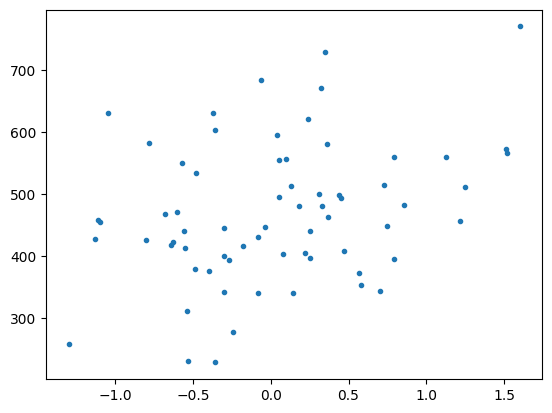

In [67]:
from matplotlib import pyplot as plt
plt.plot(sst['nino34'],ppt['ppt'],'.')
df


### 2. OLS: Z_rain = b0 + b1 * Z_SST

In [68]:

X = sm.add_constant(df["z_sst"])          # adds the intercept column
model = sm.OLS(df["z_rain"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 z_rain   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     6.855
Date:                Wed, 11 Nov 2026   Prob (F-statistic):             0.0110
Time:                        20:18:11   Log-Likelihood:                -91.206
No. Observations:                  67   AIC:                             186.4
Df Residuals:                      65   BIC:                             190.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4.476e-16      0.117  -3.82e-15      1.0

In [69]:
b1 = model.params["z_sst"]                # slope (= correlation r for z-scores)
sd = np.sqrt(1 - model.rsquared)      # residual standard error, SSR/(n-2)
print(f"\nslope b1 = {b1:.3f}, r = {np.sqrt(model.rsquared):.3f}")
print(f"residual SE = sqrt(1 - r^2) = {sd:.3f}")



slope b1 = 0.309, r = 0.309
residual SE = sqrt(1 - r^2) = 0.951


### 3. posterior tercile

In [70]:
# normal t-statistics
t = norm.ppf(2 / 3)
z_sst = 1.25
print(f"t = {t:.3f}")

t = 0.431


In [72]:
z_rain = model.predict([[1, z_sst]])[0]   # predicted mean rainfall z-score
print(z_rain)

0.38608833000094656


In [73]:
bn = norm.cdf(-t, loc=z_rain, scale=sd)
an = norm.sf(t, loc=z_rain, scale=sd)
n = 1-bn-an
print(f'BN: {100*bn:.0f}')
print(f'N:  {100*n:.0f}')
print(f'AN: {100*an:.0f}')

BN: 20
N:  32
AN: 48
